In [209]:
import pandas as pd
import numpy as np
import glob
from tqdm import tqdm
import datetime as dt

## Unify Information from each CSV

In [36]:
datasets = glob.glob("./data/*.csv")

# We want to reconstruct a df with all available information
expected_columns = ['Genero_Usuario', 'Edad_Usuario', 'Bici', 'Ciclo_Estacion_Retiro',
       'Fecha_Retiro', 'Hora_Retiro', 'Ciclo_EstacionArribo', 'Fecha_Arribo',
       'Hora_Arribo']

df = pd.DataFrame(columns=expected_columns)


for dataset in tqdm(datasets):
    df_csv = pd.read_csv(dataset)
    
    if not (list(df_csv.columns) == expected_columns): 
        print(f'Dataset: {dataset} contains unexpected columns: {df_csv.columns}')
        continue
    
    df = pd.concat([df, df_csv], axis=0, ignore_index=True)

100%|██████████| 22/22 [08:22<00:00, 22.85s/it]


### Export Joined CSV

In [ ]:
df.to_csv('joined_data.csv')

## General Dataset Analisis

### Basic Analisis

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35612262 entries, 0 to 35612261
Data columns (total 9 columns):
 #   Column                 Dtype 
---  ------                 ----- 
 0   Genero_Usuario         object
 1   Edad_Usuario           object
 2   Bici                   object
 3   Ciclo_Estacion_Retiro  object
 4   Fecha_Retiro           object
 5   Hora_Retiro            object
 6   Ciclo_EstacionArribo   object
 7   Fecha_Arribo           object
 8   Hora_Arribo            object
dtypes: object(9)
memory usage: 2.4+ GB


In [38]:
df.describe()

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
count,35612234,35610666.0,35612262,35612262,35612262,35612262,35612262,35612262,35612262
unique,4,92.0,7994,683,705,70395,683,669,75839
top,M,30.0,2708642,271-272,27/02/2025,18:08:30,271-272,27/02/2025,18:26:04
freq,24149339,1810523.0,6615,242851,75347,1078,415376,75314,964


In [39]:
df.isna().sum()

Genero_Usuario             28
Edad_Usuario             1596
Bici                        0
Ciclo_Estacion_Retiro       0
Fecha_Retiro                0
Hora_Retiro                 0
Ciclo_EstacionArribo        0
Fecha_Arribo                0
Hora_Arribo                 0
dtype: int64

### Check for duplication after Joining the data

In [43]:
duplicates = np.sum([df.duplicated()])

In [46]:
print(duplicates)

0


No duplicates after join

### Na values analisis

#### Genero_Usuario

<Axes: xlabel='Genero_Usuario'>

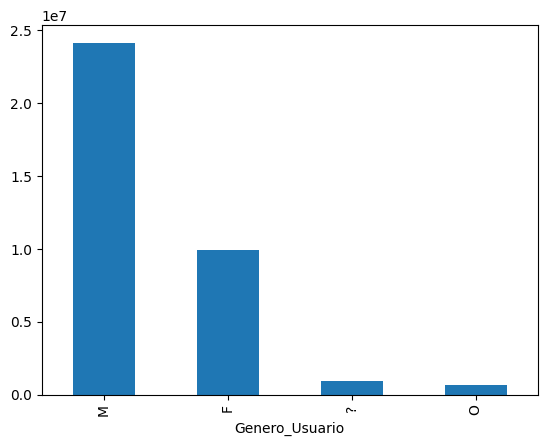

In [40]:
df['Genero_Usuario'].value_counts().plot(kind='bar')

Since having the category '?' is the same as not having information, we will cast those values to nan for the moment so as not to have missleading categories. By the moment we appreciate that Male antries dominate the dataset, meanwhile Others is a really minor group.

In [44]:
df.loc[df['Genero_Usuario'] == '?','Genero_Usuario'] = np.nan

In [48]:
df['Genero_Usuario'].isna().sum()

np.int64(911677)

#### Edad Usuario

Since user age is stored as an string, we will first convert to int (all values have no decimals)

In [69]:
df['Edad_Usuario'] = df['Edad_Usuario'].astype('Int64')

In [95]:
df['Edad_Usuario'].nlargest(50)

25762982    162
25765039    162
3172526     143
3188767     143
14767580    143
14776814    143
15003790    143
34842396    130
34848490    130
34856625    130
34861220    130
34918315    130
34925401    130
27454411    126
13436877    125
13451273    125
13513839    125
13534227    125
13579099    125
13640369    125
13654478    125
13770288    125
13881507    125
13940055    125
14003813    125
14018980    125
14071811    125
14133475    125
14207591    125
14268544    125
14346417    125
14398548    125
14655895    125
14673037    125
14717714    125
14737292    125
14860812    125
15053239    125
15065540    125
15234681    125
15253557    125
15299814    125
15437700    125
15623934    125
15698810    125
15973663    125
15992875    125
16044496    125
16176526    125
16197339    125
Name: Edad_Usuario, dtype: Int64

no human has ever lived 162 years, we shall deal with those imposible outliers

set 115 as hard Upper limit

In [93]:
imposible_ages = np.sum(df['Edad_Usuario'] >= 110)
imposible_ages

np.int64(243)

In [94]:
imposible_ages / len(df)

np.float64(6.8234924251652425e-06)

Since the proportion is around 7% we will just termporarily convert those values to nan so as not to loose the rest of values

In [101]:
df['Edad_Usuario'].nsmallest(5)

1254     16
1594     16
53585    16
70274    16
80342    16
Name: Edad_Usuario, dtype: Int64

16 years old is the minimum age for using ecobici, so it is fine

count    35610666.0
mean      34.381273
std        9.834739
min            16.0
25%            27.0
50%            32.0
75%            39.0
max           162.0
Name: Edad_Usuario, dtype: Float64

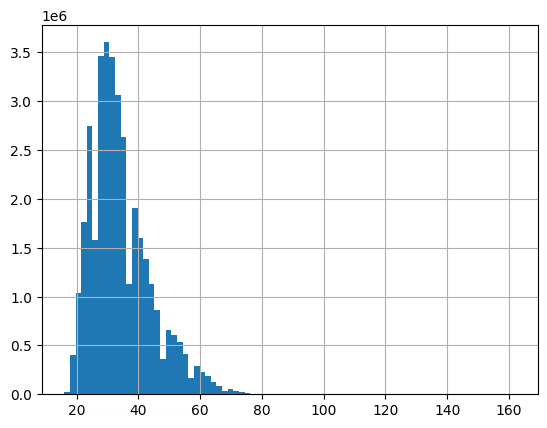

In [98]:
df['Edad_Usuario'].hist(bins=80)
df['Edad_Usuario'].describe()

We can see that ages follow a lognormal distribution with mean around 34


#### Bici (Bycicle ID)

This is an integer so we will cast it as such

In [103]:
df['Bici'] = df['Bici'].astype('int64')

In [105]:
df['Bici'].describe()

count    3.561226e+07
mean     5.471621e+06
std      2.024366e+06
min      2.000461e+06
25%      3.739224e+06
50%      5.483300e+06
75%      7.221740e+06
max      8.999708e+06
Name: Bici, dtype: float64

<Axes: >

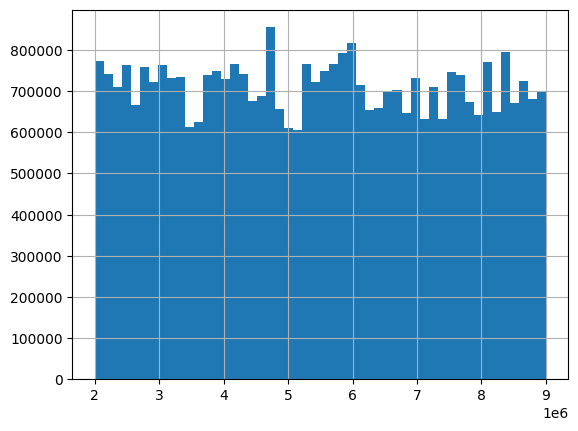

In [108]:
df['Bici'].hist(bins=50)

As expected this column has no tendency, it also has no atipical or missing values, we can continue the analisis

#### Ciclo Estación Retiro (Station ID of the Ecobici retire station)

In [ ]:
df['Ciclo_Estacion_Retiro'].value_counts()

<bound method Series.count of Ciclo_Estacion_Retiro
271-272                                      242851
548                                          213171
027                                          199887
064                                          185248
208                                          180525
                                              ...  
Temporal - 2da Sección Bosque Chapultepec       399
1000                                            139
Temporal 2                                      130
Temporal 3                                       16
Temporal 4                                        6
Name: count, Length: 683, dtype: int64>

We see there are some non complitly integer values (e. g. '390-391') thus we shouldn't cast to integer

<Axes: >

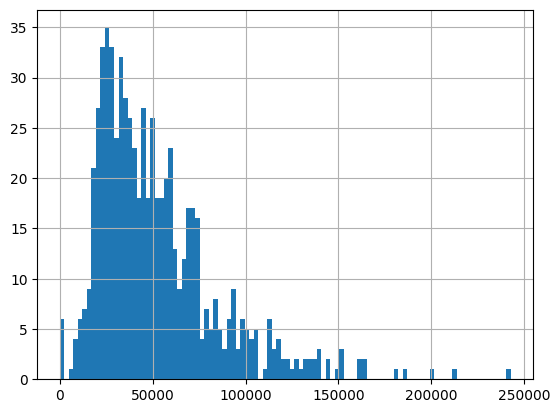

In [119]:
df['Ciclo_Estacion_Retiro'].value_counts().hist(bins = 100)

This is a pretty insightful chart, since it reveals the retire usage of stations is distributed lognormally (There are a lot more less used stations than more used). Also note that there are quite some stations with apparent 0 retires, this is something worth investigating.

In [128]:
df['Ciclo_Estacion_Retiro'].value_counts().nsmallest(8)

Ciclo_Estacion_Retiro
Temporal 4                                      6
Temporal 3                                     16
Temporal 2                                    130
1000                                          139
Temporal - 2da Sección Bosque Chapultepec     399
Temporal 1                                    570
665                                          7165
664                                          7345
Name: count, dtype: int64

 Ecobici has placed temporary stations in Mexico City, typically setting them up as mobile corrals or pop-up bike stations (biciestaciones temporales) for major events, festivals, and high-traffic gatherings rather than permanent neighborhood coverage. If we are going to run simulation, having those stations may be counter producing. Lets sum all Temporal rows

In [ ]:
temporal_rows = np.sum(df['Ciclo_Estacion_Retiro'].value_counts().nsmallest(6))
temporal_rows

np.int64(1260)

In [139]:
temporal_rows / len(df)

np.float64(3.5381071834190145e-05)

We can see the portion is extreamly small in comparison to the database lenght, so for the sake of better simulations we can eliminate those whole rows without looseing much information from other featues (that is biases aswell for the temporality of the station)

In [143]:
temporal_stations = list(df['Ciclo_Estacion_Retiro'].value_counts().nsmallest(6).index)
temporal_stations

['Temporal 4',
 'Temporal 3',
 'Temporal 2',
 '1000',
 'Temporal - 2da Sección Bosque Chapultepec',
 'Temporal 1']

In [146]:
deletion_mask = df['Ciclo_Estacion_Retiro'].isin(temporal_stations)
np.sum(deletion_mask)

np.int64(1260)

In [147]:
df = df[~deletion_mask]

In [149]:
np.sum(df['Ciclo_Estacion_Retiro'] == 'Temporal 4')

np.int64(0)

#### Ciclo Estacion Arribo (Station ID of the Ecobici arrival station)


In [ ]:
df['Ciclo_EstacionArribo'].value_counts()

Ciclo_EstacionArribo
271-272                                      415371
548                                          233650
014                                          215142
027                                          207262
064                                          195947
                                              ...  
Temporal 1                                      474
Temporal - 2da Sección Bosque Chapultepec       268
Temporal 2                                      105
Temporal 3                                       16
Temporal 4                                        9
Name: count, Length: 683, dtype: int64

<Axes: >

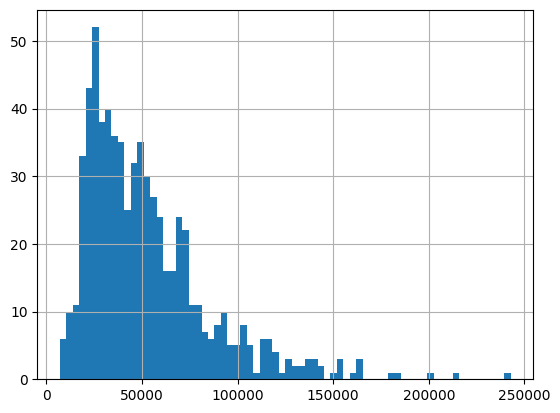

In [158]:
df['Ciclo_Estacion_Retiro'].value_counts().hist(bins = 70)

Similar to retire chart this chart shows the arribal usage of stations is distributed lognormally (There are a lot more less used stations than more used). Also note that there are no stations with apparent 0 retires, let's investigate.

In [162]:
stations_with_less_entries = df['Ciclo_Estacion_Retiro'].value_counts().nsmallest(7)
stations_with_less_entries

Ciclo_Estacion_Retiro
665     7165
664     7345
687     7717
662     7798
666     8765
707     9991
694    10783
Name: count, dtype: int64

Unlike the retire distribution this distribution doesn't contain temporal station's data, so no need to purge the df more

#### Fecha Retiro

Theese are dates with no hour, so we will cast to an appropiate type

In [165]:
df['Fecha_Retiro'] = pd.to_datetime(df['Fecha_Retiro'], format="%d/%m/%Y", errors="raise")

We casted with errors raise and no errors were raised, then the data is correct format-wise

<Axes: >

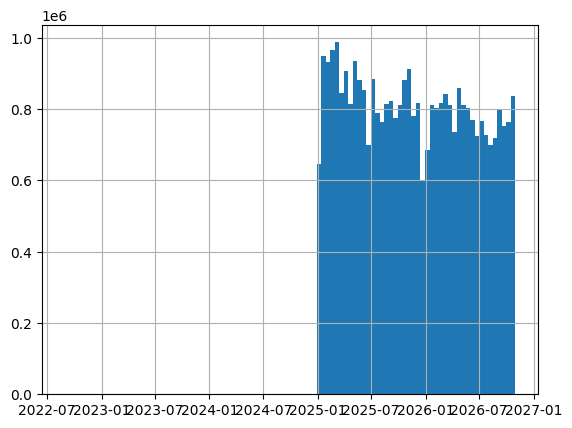

In [169]:
df['Fecha_Retiro'].hist(bins = 100)

The histogram is not centered exactly on the data which suggest the presence of outliers, we will check

In [172]:
df['Fecha_Retiro'].nsmallest(50)

18594279   2022-08-28
30034677   2022-10-03
6946101    2022-12-13
1115751    2023-02-04
3993453    2023-04-30
19542804   2023-08-14
2447761    2023-09-09
11333571   2023-10-17
25639029   2023-11-14
21819645   2024-02-25
10277271   2024-03-11
7499947    2024-04-09
8151091    2024-05-13
3035857    2024-05-24
3998061    2024-05-26
7393501    2024-06-06
10049554   2024-06-07
10888917   2024-07-07
10881415   2024-07-15
11384267   2024-07-24
23622077   2024-08-04
1116290    2024-08-10
3431845    2024-09-16
22812794   2024-09-26
18937360   2024-10-14
2525727    2024-10-31
5310517    2024-11-17
1455091    2024-11-25
2022728    2024-11-30
8143445    2024-11-30
3748559    2024-12-05
5955286    2024-12-12
1011552    2024-12-18
315907     2024-12-23
1117822    2024-12-28
41178      2024-12-29
0          2024-12-31
1          2024-12-31
2          2024-12-31
3          2024-12-31
4          2024-12-31
5          2024-12-31
6          2024-12-31
7          2024-12-31
8          2024-12-31
9         

This analisis is scoped to begin in 2025, then rows before that time shuld be erassed as they are erratic and most likely a mistake from the filter sistem

In [191]:
deletion_mask = df['Fecha_Retiro'] < pd.Timestamp("2025-01-01")
np.sum(deletion_mask)

np.int64(129)

delete the entries

In [ ]:
df = df[~deletion_mask]

In [193]:
deletion_mask = df['Fecha_Retiro'] < pd.Timestamp("2024-01-01")
np.sum(deletion_mask)

np.int64(0)

#### Future bound of data

In [188]:
df['Fecha_Retiro'].nlargest(5)

35572656   2026-10-31
35572666   2026-10-31
35572677   2026-10-31
35572684   2026-10-31
35572686   2026-10-31
Name: Fecha_Retiro, dtype: datetime64[us]

No problems in upper bound of data

#### Fecha Arribo

In [185]:
df['Fecha_Arribo'] = pd.to_datetime(df['Fecha_Arribo'], format="%d/%m/%Y", errors="raise")

In [190]:
df['Fecha_Arribo'].nsmallest(50)

0    2025-01-01
1    2025-01-01
2    2025-01-01
3    2025-01-01
4    2025-01-01
5    2025-01-01
6    2025-01-01
7    2025-01-01
8    2025-01-01
9    2025-01-01
10   2025-01-01
11   2025-01-01
12   2025-01-01
13   2025-01-01
14   2025-01-01
15   2025-01-01
16   2025-01-01
17   2025-01-01
18   2025-01-01
19   2025-01-01
20   2025-01-01
21   2025-01-01
22   2025-01-01
23   2025-01-01
24   2025-01-01
25   2025-01-01
26   2025-01-01
27   2025-01-01
28   2025-01-01
29   2025-01-01
30   2025-01-01
31   2025-01-01
32   2025-01-01
33   2025-01-01
34   2025-01-01
35   2025-01-01
36   2025-01-01
37   2025-01-01
38   2025-01-01
39   2025-01-01
40   2025-01-01
41   2025-01-01
42   2025-01-01
43   2025-01-01
44   2025-01-01
45   2025-01-01
46   2025-01-01
47   2025-01-01
48   2025-01-01
49   2025-01-01
Name: Fecha_Arribo, dtype: datetime64[us]

Lower bound is ok

In [194]:
df['Fecha_Arribo'].nlargest(50)

35572580   2026-10-31
35572581   2026-10-31
35572582   2026-10-31
35572583   2026-10-31
35572584   2026-10-31
35572585   2026-10-31
35572586   2026-10-31
35572587   2026-10-31
35572588   2026-10-31
35572589   2026-10-31
35572590   2026-10-31
35572591   2026-10-31
35572592   2026-10-31
35572593   2026-10-31
35572594   2026-10-31
35572595   2026-10-31
35572596   2026-10-31
35572597   2026-10-31
35572598   2026-10-31
35572599   2026-10-31
35572600   2026-10-31
35572601   2026-10-31
35572602   2026-10-31
35572603   2026-10-31
35572604   2026-10-31
35572605   2026-10-31
35572606   2026-10-31
35572607   2026-10-31
35572608   2026-10-31
35572609   2026-10-31
35572610   2026-10-31
35572611   2026-10-31
35572612   2026-10-31
35572613   2026-10-31
35572614   2026-10-31
35572615   2026-10-31
35572616   2026-10-31
35572617   2026-10-31
35572618   2026-10-31
35572619   2026-10-31
35572620   2026-10-31
35572621   2026-10-31
35572622   2026-10-31
35572623   2026-10-31
35572624   2026-10-31
35572625  

Upper bound is ok

<Axes: >

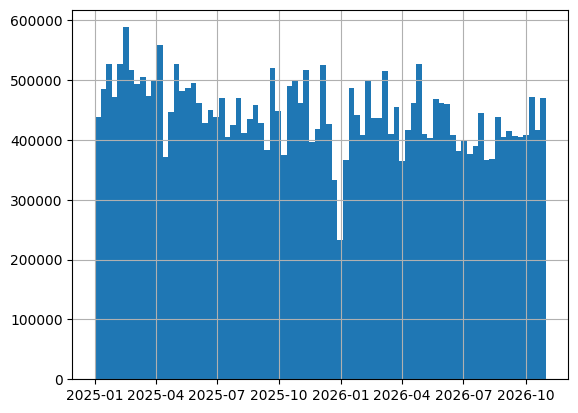

In [195]:
df['Fecha_Arribo'].hist(bins=80)

#### Hora Retiro

ECOBICI stations stop unlocking bikes at 12:30 a.m. (00:30), operating daily from 5:00 a.m. to 12:30 a.m and takes bicicles all day

In [207]:
df['Hora_Retiro'] = pd.to_datetime(df['Hora_Retiro'], format="%H:%M:%S", errors="raise")

Lets filter for invalid 

In [221]:
invalid_retiros_mask = (
    (df['Hora_Retiro'].dt.time > dt.time(0, 30, 0)) & 
    (df['Hora_Retiro'].dt.time < dt.time(5, 0, 0))
)

In [222]:
len(invalid_retiros_mask)

35610864

Since it is a small portion we can get rid of them

In [223]:
df = df[~invalid_retiros_mask]

<Axes: >

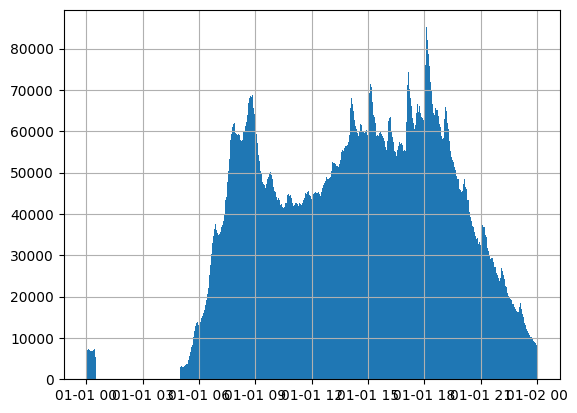

In [226]:
df['Hora_Retiro'].hist(bins = 1000)

#### Hora Arribo

For this there are no invalid times, so we leave them as they are

In [227]:
df['Hora_Arribo'] = pd.to_datetime(df['Hora_Arribo'], format="%H:%M:%S", errors="raise")

<Axes: >

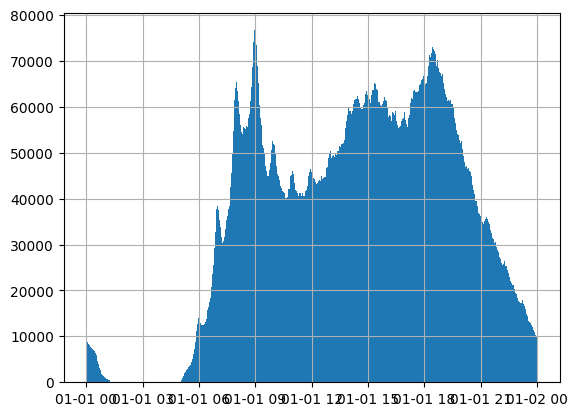

In [228]:
df['Hora_Arribo'].hist(bins = 1000)

As expected this histogram heavily resembles the previous one as they are heavily dependent to one another

In [230]:
df.info()

<class 'pandas.DataFrame'>
Index: 35610302 entries, 12 to 35612261
Data columns (total 9 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Genero_Usuario         object        
 1   Edad_Usuario           Int64         
 2   Bici                   int64         
 3   Ciclo_Estacion_Retiro  object        
 4   Fecha_Retiro           datetime64[us]
 5   Hora_Retiro            datetime64[us]
 6   Ciclo_EstacionArribo   object        
 7   Fecha_Arribo           datetime64[us]
 8   Hora_Arribo            datetime64[us]
dtypes: Int64(1), datetime64[us](4), int64(1), object(3)
memory usage: 2.7+ GB
